# This is a _Regression Model_ of Houston's 2024 Housing Costs from Zillow.

This is an analysis of the City of Houston's housing 2024 prices - with 25,000+ listings scrapped off of Zillow.


These are the libraries I used for the analysis of Zillow's housing analysis. SQLite was my database of choice, due to the relatively compact amounts of data provided.

In [46]:
import pandas as pd
import sqlite3
import numpy as np
import matplotlib.pyplot as plt

In [47]:
table_name = "properties"
db_path = "houston_housing.db"
conn = sqlite3.connect(db_path)
cursor = conn.cursor()


cursor.execute(f"PRAGMA table_info({table_name});")
schema_info = cursor.fetchall()

int_column = [col[1] for col in schema_info if "INT" in col[2].upper()]

if int_column:
    print(f"The following columns are available: {int_column}")


The following columns are available: ['zpid', 'isListingClaimedByCurrentSignedInUser', 'isCurrentSignedInAgentResponsible', 'bedrooms', 'bathrooms', 'price', 'yearBuilt', 'isCurrentSignedInUserVerifiedOwner', 'isRentalListingOffMarket', 'cityId', 'isUndisclosedAddress', 'isShowcaseListing', 'isPremierBuilder', 'monthlyHoaFee', 'livingArea', 'livingAreaValue', 'zestimate', 'rentZestimate', 'pageViewCount', 'favoriteCount', 'daysOnZillow', 'ssid', 'isZillowOwned', 'hasApprovedThirdPartyVirtualTourUrl', 'photoCount', 'lotSize', 'stateId', 'hasBadGeocode', 'hasPublicVideo', 'tourViewCount', 'hideZestimate', 'isPreforeclosureAuction', 'isHousingConnector', 'isRecentStatusChange', 'isNonOwnerOccupied', 'isFeatured', 'isRentalsLeadCapMet', 'isPaidMultiFamilyBrokerId', 'countyId', 'isValid']


In [48]:
df_sql1 = """
SELECT bedrooms, bathrooms, "yearBuilt", "monthlyHoaFee", "livingArea",
    "livingAreaValue", zestimate, "rentZestimate", "daysOnZillow", price
FROM properties;
"""

df = pd.read_sql(df_sql1, conn)

df = df.apply(pd.to_numeric, errors="coerce")

cols_keep_name = ["yearBuilt", "zestimate", "rentZestimate"]
cols_fill = df.columns.difference(cols_keep_name)
df[cols_fill] = df[cols_fill].fillna(0)

print(df.isna().sum())

df = df.dropna().reset_index(drop=True)

X_train = df.drop(columns=["price"]).to_numpy()
y_train = df["price"].to_numpy()

print(f"X shape: {X_train.shape}, X Type: {type(X_train)}")
print(f"y shape: {y_train.shape}, y Type: {type(y_train)}")

conn.close()

w_init = np.zeros(X_train[0,:].shape)
b_init = 0

bedrooms           0
bathrooms          0
yearBuilt          1
monthlyHoaFee      0
livingArea         0
livingAreaValue    0
zestimate          9
rentZestimate      6
daysOnZillow       0
price              0
dtype: int64
X shape: (76, 9), X Type: <class 'numpy.ndarray'>
y shape: (76,), y Type: <class 'numpy.ndarray'>


Text(0, 0.5, 'y')

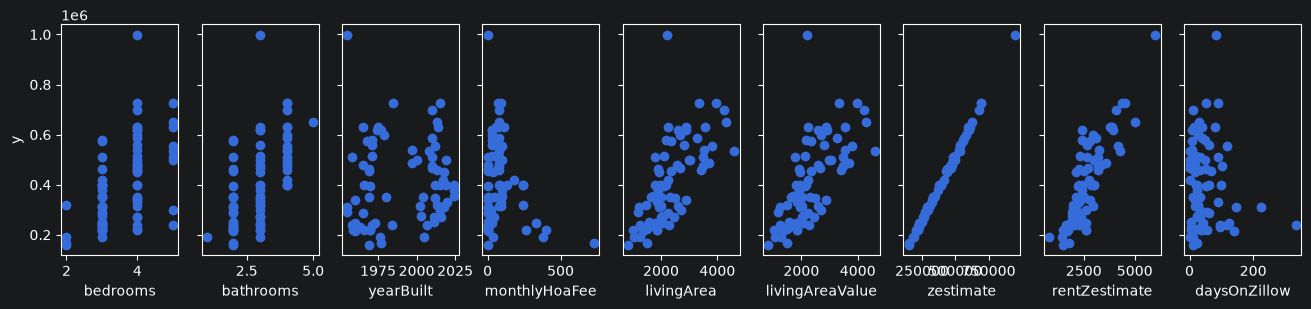

In [64]:
X_features = ["bedrooms", "bathrooms", "yearBuilt", "monthlyHoaFee", "livingArea", "livingAreaValue", "zestimate", "rentZestimate", "daysOnZillow"]

fig,ax=plt.subplots(1, 9, figsize=(16,3), sharey=True)

for i in range(len(ax)):
    ax[i].scatter(X_train[:,i],y_train)
    ax[i].set_xlabel(X_features[i])
ax[0].set_ylabel("y")

In [70]:
def zscaled_features():
    mu = X_train.mean(axis=0)
    sigma = X_train.std(axis=0)
    sigma[sigma == 0] = 1

    x_features_scaled = (X_train - mu) / sigma
    return x_features_scaled

zscaled_features()

array([[ 5.17857510e-01,  1.10971401e-01,  1.22986387e+00,
        -3.37651572e-01, -4.32373610e-01, -4.32373610e-01,
         3.08359934e-01, -6.12856771e-01, -5.55506312e-01],
       [ 5.17857510e-01,  1.31580376e+00,  8.85909302e-01,
        -5.52018918e-03,  2.33815663e+00,  2.33815663e+00,
         1.82411384e+00,  1.61678012e+00, -6.88209211e-01],
       [ 1.82976320e+00,  1.31580376e+00,  7.99920660e-01,
         1.19604099e-02,  2.77598966e+00,  2.77598966e+00,
         8.99812268e-01,  1.84085862e+00, -8.96742340e-01],
       [ 1.82976320e+00,  1.10971401e-01,  4.55966090e-01,
        -5.52018918e-03,  8.93187005e-01,  8.93187005e-01,
         6.75186222e-01,  3.89365010e-01, -8.96742340e-01],
       [ 1.82976320e+00,  1.31580376e+00,  1.10088091e+00,
         1.25584304e-01,  2.01128954e+00,  2.01128954e+00,
         1.92101135e+00,  2.06939641e+00,  7.90480243e-01],
       [ 5.17857510e-01,  1.31580376e+00,  1.01489227e+00,
        -5.52018918e-03,  1.34911231e+00,  1.349112

In [32]:
def prediction(x, w, b):

    p = np.dot(x, w) + b
    return p

x_vec = X_train[0,:]

print(x_vec)

f_wb = prediction(x_vec, w_init, b_init)

print(f"f_wb shape {f_wb.shape}, initial prediction: {f_wb}")

[4.000e+00 3.000e+00 2.018e+03 3.900e+01 1.943e+03 1.943e+03 4.397e+05
 2.099e+03 1.800e+01]
f_wb shape (), initial prediction: 0.0


In [ ]:
def compute_cost(X, y, w, b):
    err = X @ w + b - y
    return (err @ err) / (2 * len(y))

cost = compute_cost(X_train, y_train, w_init, b_init)
print(cost)